# 03 · Solo do MapBiomas nas áreas de soja (etapa 02b, versão 1)

O Battisti & Sentelhas (2019) dá peso igual aos 3 solos em todo o Brasil. Aqui cada célula de 1° pondera os 3 solos pela **área de soja** (MapBiomas Cobertura col. 10, classe 39, 2016) em cada classe de argila média de 0–80 cm (MapBiomas Solo col. 3):

| Classe | Argila 0–80 cm | Solo do artigo | Água disponível |
|---|---|---|---|
| 1 | < 30% | franco-arenoso | 48 mm |
| 2 | 30–59% | argilo-arenoso | 80 mm |
| 3 | ≥ 59% | argiloso | 120 mm |

Não há simulação nova: as rodadas da v2 são só reponderadas. A versão 2 desta etapa vai trocar os 3 solos fixos por perfis do MapBiomas com pedotransferência brasileira.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
import analise_bs2019 as an
DIR_FIG = RAIZ / "resultados" / "solo_mapbiomas"; DIR_FIG.mkdir(parents=True, exist_ok=True)
sim = an.carregar()
fr = pd.read_csv(RAIZ / "dados" / "processados" / "fracoes_solo_mapbiomas_soja2016.csv")
print(f"{len(fr)} células com soja | {fr.soja_ha.sum() / 1e6:.1f} Mha")

359 células com soja | 32.7 Mha


## Fração da área de soja em cada solo

,francoarenoso,argiloarenoso,argiloso
zona_bs,,,
1.0,47.0,52.0,1.0
2.0,56.0,43.0,1.0
3.0,30.0,61.0,9.0
4.0,11.0,83.0,6.0
5.0,82.0,17.0,1.0
6.0,41.0,40.0,19.0
7.0,34.0,66.0,0.0
8.0,13.0,56.0,31.0
9.0,4.0,30.0,66.0


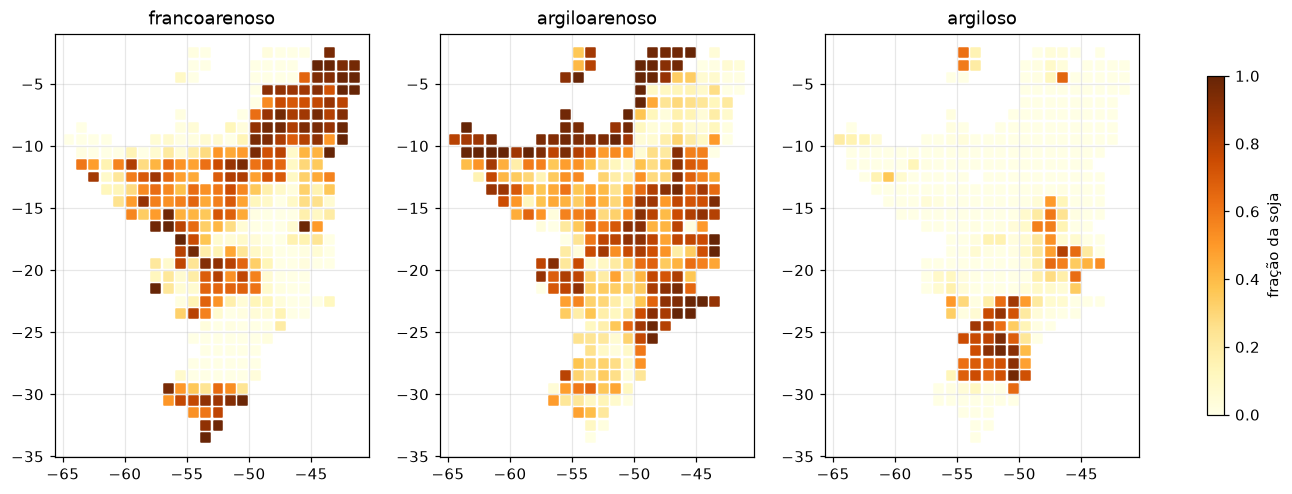

In [2]:
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
for ax, s in zip(axs, ["francoarenoso", "argiloarenoso", "argiloso"]):
    sc = ax.scatter(fr.lon, fr.lat, c=fr[f"f_{s}"], cmap="YlOrBr", vmin=0, vmax=1, marker="s", s=34)
    ax.set_title(s); ax.set_aspect("equal")
plt.colorbar(sc, ax=axs, shrink=0.8, label="fração da soja")
fig.savefig(DIR_FIG / "fracoes_solo.png", bbox_inches="tight")
z = fr.merge(pd.read_csv(an.PONTOS)[["lon", "lat", "zona_bs"]], on=["lon", "lat"])
(100 * z.groupby("zona_bs").apply(lambda g: g[["francoarenoso", "argiloarenoso", "argiloso"]].sum() / g.soja_ha.sum())).round(0)

## Peso igual × peso MapBiomas: comparação com o IBGE por microrregião

peso igual: r = 0.40 | n = 267 | viés = -624 kg/ha | RMSE = 777 kg/ha
MapBiomas : r = 0.44 | n = 267 | viés = -586 kg/ha | RMSE = 760 kg/ha


,n,r_peso_igual,r_mapbiomas,sim_igual,sim_mapbiomas,ibge
zona_bs,,,,,,
1.0,14.0,0.75,0.80,2790.29,2769.53,2911.48
2.0,14.0,0.49,0.62,2960.20,2851.64,3044.30
3.0,71.0,0.17,0.02,2521.60,2590.39,2761.23
4.0,4.0,-0.72,-0.75,1970.26,1926.20,2851.37
5.0,16.0,0.44,0.62,1640.53,1482.45,2569.43
6.0,17.0,0.52,0.37,1339.57,1215.15,2256.17
7.0,1.0,NaN,NaN,886.97,852.47,3359.00
8.0,16.0,0.50,0.52,1954.76,2058.62,2741.86
9.0,79.0,0.31,0.35,1902.78,2072.66,2839.72


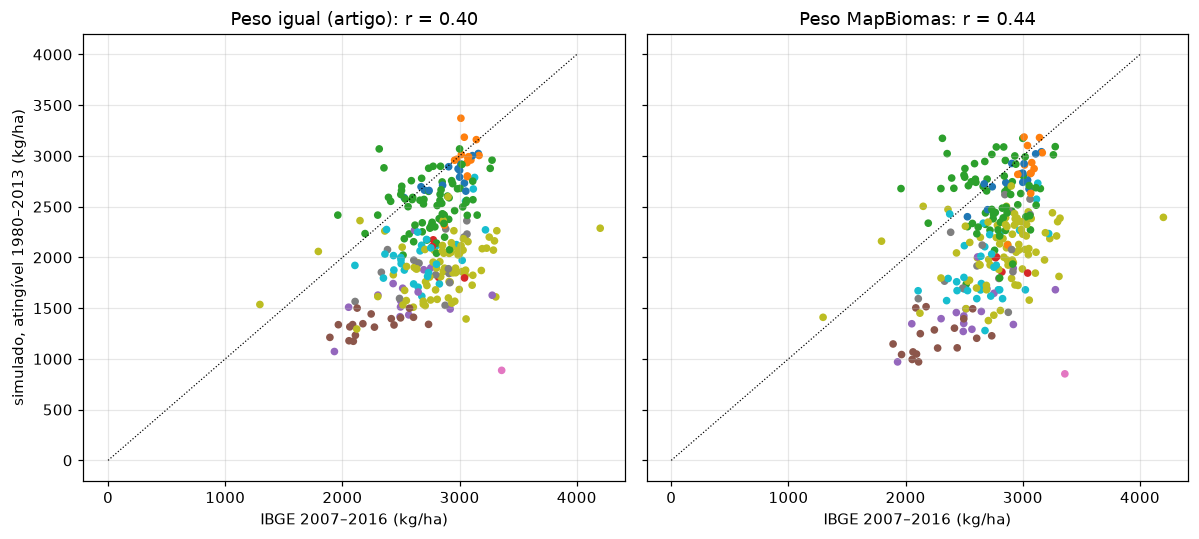

In [3]:
est_i = an.estatisticas_ponto(sim).merge(fr[["lon", "lat"]], on=["lon", "lat"])
est_p = an.estatisticas_ponto_ponderadas(sim, fr)
mi, ri = an.comparar_ibge_microrregiao(sim, est_i)
mp, rp = an.comparar_ibge_microrregiao(sim, est_p)
comp = pd.DataFrame({"n": ri.n, "r_peso_igual": ri.r, "r_mapbiomas": rp.r,
                     "sim_igual": ri.sim_media, "sim_mapbiomas": rp.sim_media, "ibge": ri.ibge_media}).round(2)
comp.to_csv(DIR_FIG / "comparacao_ibge_pesos.csv")
for nome, m in [("peso igual", mi), ("MapBiomas", mp)]:
    print(f"{nome:10s}: r = {m.sim.corr(m.ibge):.2f} | n = {len(m)} | viés = {(m.sim - m.ibge).mean():+.0f} kg/ha | "
          f"RMSE = {np.sqrt(((m.sim - m.ibge) ** 2).mean()):.0f} kg/ha")
fig, axs = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, (nome, m) in zip(axs, [("Peso igual (artigo)", mi), ("Peso MapBiomas", mp)]):
    ax.scatter(m.ibge, m.sim, c=m.zona_bs, cmap="tab10", vmin=0.5, vmax=10.5, s=16)
    ax.plot([0, 4000], [0, 4000], "k:", lw=0.8); ax.set_title(f"{nome}: r = {m.sim.corr(m.ibge):.2f}")
    ax.set_xlabel("IBGE 2007–2016 (kg/ha)")
axs[0].set_ylabel("simulado, atingível 1980–2013 (kg/ha)")
fig.tight_layout(); fig.savefig(DIR_FIG / "ibge_pesos.png", bbox_inches="tight")
comp

## Versão 2: perfis completos do MapBiomas com pedotransferência brasileira

Cada célula tem até 3 perfis (classes de argila), cada um com a média dos pixels de soja:
- textura: MapBiomas Solo col. 3 (10 camadas de 0–100 cm);
- densidade e forma do perfil de carbono: SoilGrids, com o carbono escalado para que o estoque de 0–30 cm iguale o do MapBiomas (o SoilGrids superestima ~50% nas lavouras);
- retenção de água: Medrado & Lima (2014), modelo completo, com a matéria orgânica limitada a 5,75% (faixa de validação do artigo); densidade de partículas 2,65 Mg/m³;
- raiz: SRGF de Battisti & Sentelhas (2019), cortado na profundidade de 50% de pedregosidade do MapBiomas.

O potencial da capacidade de campo é testado em −10 e −33 kPa. O resto segue a configuração v2.

In [4]:
res = {"v2: 3 solos, peso igual": est_i, "v2: 3 solos, peso MapBiomas": est_p}
for h in (10, 33):
    pasta = RAIZ / "resultados" / "solo_mapbiomas" / f"sim_cc{h}kPa"
    if any(pasta.glob("*.csv")):
        e, _ = an.estatisticas_solo_mb(pasta)
        res[f"perfis MapBiomas, CC −{h} kPa"] = e
linhas = []
for nome, e in res.items():
    m, r = an.comparar_ibge_microrregiao(sim, e)
    linhas.append(dict(variante=nome, n=len(m), r=m.sim.corr(m.ibge), vies=(m.sim - m.ibge).mean(),
                       rmse=np.sqrt(((m.sim - m.ibge) ** 2).mean()), **{f"r_z{int(z)}": v for z, v in r.r.items()}))
tab = pd.DataFrame(linhas).set_index("variante").round(2)
tab.to_csv(DIR_FIG / "comparacao_variantes_solo.csv")
tab

,n,r,vies,rmse,r_z1,r_z2,r_z3,r_z4,r_z5,r_z6,r_z7,r_z8,r_z9,r_z10
variante,,,,,,,,,,,,,,
"v2: 3 solos, peso igual",267,0.40,-623.88,776.87,0.75,0.49,0.17,-0.72,0.44,0.52,NaN,0.50,0.31,0.51
"v2: 3 solos, peso MapBiomas",267,0.44,-586.08,760.38,0.80,0.62,0.02,-0.75,0.62,0.37,NaN,0.52,0.35,0.48
"perfis MapBiomas, CC −10 kPa",267,0.27,-655.53,901.68,0.52,0.08,0.29,-0.59,-0.07,0.29,NaN,-0.14,0.20,0.25
"perfis MapBiomas, CC −33 kPa",267,0.24,-1471.97,1610.56,0.49,0.05,0.34,-0.54,-0.15,0.15,NaN,-0.24,0.17,0.37


## Leitura

| Variante | r com o IBGE | Viés (kg/ha) |
|---|---|---|
| 3 solos do artigo, peso igual | 0,40 | −624 |
| **3 solos do artigo, peso pela textura do MapBiomas** | **0,44** | −586 |
| Perfis MapBiomas + Medrado & Lima, CC −10 kPa | 0,27 | −656 |
| Perfis MapBiomas + Medrado & Lima, CC −33 kPa | 0,24 | −1472 |

- O peso pela textura real melhora pouco a correlação espacial com o IBGE.
- Os perfis completos com Medrado & Lima **pioram** a correlação. Com essa função, a água disponível *diminui* com a argila (r = −0,72 entre células), o oposto da suposição do artigo. Isso é coerente com Latossolos microagregados do Cerrado, onde a função foi ajustada, mas não com os solos argilosos de basalto do Sul (zona 9), onde a produtividade simulada cai e a correlação piora. Ottoni et al. (2018) já apontam que o desempenho das funções brasileiras muda com a mineralogia.
- Em todas as variantes o simulado fica **~600 kg/ha abaixo do IBGE** (−1472 com −33 kPa). Parte disso é tendência tecnológica (a média simulada cobre 1980–2013); parte, coeficientes de produtividade defasados. Isso motiva a calibração da Fase B.
- **Decisão:** a base de solo para a Fase B é a dos 3 solos do artigo com peso pela textura do MapBiomas. A pedotransferência fica como análise de sensibilidade. Na Fase B, um fator de escala da água disponível e a profundidade de raiz entram como parâmetros calibrados, junto com os coeficientes da cultivar.